# 01 · Data and exploratory analysis

**Purpose**
- Load GQA questions and scene graphs
- Describe and visualise the dataset
- Build the evaluation and calibration samples
- Download only the images those samples need

**Splits**
- `testdev_balanced` → **evaluation**, 2,500 questions (LXMERT never trained on it)
- `val_balanced` → **calibration**, 500 questions (tuning only; has scene graphs)

**Runtime:** CPU is enough (Runtime → Change runtime type → CPU)

## 1 · Setup
- Mount Drive, load the repo code, fix the seed.
- `datasets` reads GQA from the Hugging Face mirror (faster than the 1.4 GB zip).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys
REPO_DIR = "/content/drive/MyDrive/cw-mpvr"
%cd {REPO_DIR}
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

!pip install -q datasets
if "datasets" not in open("requirements.txt").read():
    open("requirements.txt", "a").write("datasets\n")

from src.utils import load_config, set_seed
from src.errorlog import log_error
from src.gitsync import save_and_push

cfg = load_config()
set_seed(cfg["seed"])
SEED = cfg["seed"]
DATA = cfg["paths"]["data"]
print("Data folder:", DATA)

Mounted at /content/drive
/content/drive/MyDrive/cw-mpvr
Data folder: /content/drive/MyDrive/cw-mpvr-data


## 2 · Helper code
- Writes `src/gqa.py`: loading, sampling and scene-graph functions.
- Kept in `src/` so notebooks 02–05 reuse the exact same code.

In [2]:
%%writefile src/gqa.py
"""GQA helpers: loading questions, scene-graph statistics, stratified sampling.

Written from notebooks/01_data_eda.ipynb; imported by later notebooks.
"""

import json
from collections import Counter

import numpy as np
import pandas as pd

HF_REPO = "lmms-lab/GQA"                          # mirror of the official GQA release
CONFIG = {"testdev": "testdev_balanced", "val": "val_balanced"}
TYPE_COLS = ["structural", "semantic"]           # GQA's two question-type labels


def load_questions(split: str) -> pd.DataFrame:
    """Load balanced GQA questions for 'testdev' or 'val' as a tidy table."""
    from datasets import load_dataset
    ds = load_dataset(HF_REPO, f"{CONFIG[split]}_instructions", split=split)
    return to_frame(ds.to_pandas(), split)


def _type(t, key):
    return (t or {}).get(key)


def _n_steps(raw: pd.DataFrame) -> pd.Series:
    """Reasoning steps = number of operations in GQA's semantic program."""
    if "semantic" in raw.columns:
        return raw["semantic"].map(lambda p: 0 if p is None else len(p))
    return raw["semanticStr"].map(lambda s: len(str(s).split("->")) if s else 0)


def to_frame(raw: pd.DataFrame, split: str) -> pd.DataFrame:
    """Keep only the columns the project needs."""
    df = pd.DataFrame({
        "id": raw["id"].astype(str),
        "imageId": raw["imageId"].astype(str),
        "question": raw["question"],
        "answer": raw["answer"],
        "structural": raw["types"].map(lambda t: _type(t, "structural")),
        "semantic": raw["types"].map(lambda t: _type(t, "semantic")),
        "detailed": raw["types"].map(lambda t: _type(t, "detailed")),
        "n_steps": _n_steps(raw),
    })
    df["q_words"] = df["question"].str.split().str.len()
    df["split"] = split
    return df


def stratified_sample(df: pd.DataFrame, n: int, by=TYPE_COLS, seed: int = 42) -> pd.DataFrame:
    """Proportional stratified sample of n rows.

    Each stratum (e.g. structural x semantic cell) gets n * its share of the data,
    rounded with the largest-remainder rule so the total is exactly n.
    """
    sizes = df.groupby(by).size()
    quota = sizes / sizes.sum() * n
    take = np.floor(quota).astype(int)
    extra = (quota - take).sort_values(ascending=False, kind="mergesort").index[: n - take.sum()]
    take.loc[extra] += 1
    parts = [g.sample(take.loc[k], random_state=seed) for k, g in df.groupby(by) if take.loc[k] > 0]
    return pd.concat(parts).sample(frac=1, random_state=seed).reset_index(drop=True)


def load_scene_graphs(path: str) -> dict:
    with open(path) as f:
        return json.load(f)


def scene_graph_stats(sg: dict) -> tuple[pd.DataFrame, Counter]:
    """Per-image object / attribute / relation counts, plus object-name frequencies."""
    rows, names = [], Counter()
    for img, g in sg.items():
        objs = list(g["objects"].values())
        names.update(o["name"] for o in objs)
        rows.append({
            "imageId": img,
            "n_objects": len(objs),
            "n_attributes": sum(len(o["attributes"]) for o in objs),
            "n_relations": sum(len(o["relations"]) for o in objs),
        })
    return pd.DataFrame(rows), names

Writing src/gqa.py


In [3]:
import importlib, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import src.gqa as gqa
importlib.reload(gqa)

# plot style: thin marks, light grid, consistent colours
TEST_C, VAL_C, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10, "legend.frameon": False,
})
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

def savefig(name):
    plt.savefig(f"figures/{name}.png")
    plt.show()

## 3 · Load the questions
- Both splits come with question, answer, image ID, question types and the reasoning program.
- First run downloads ~70 MB; later runs use the cache.

In [4]:
test = gqa.load_questions("testdev")
val  = gqa.load_questions("val")
print(f"testdev: {len(test):,} questions | {test.imageId.nunique():,} images")
print(f"val:     {len(val):,} questions | {val.imageId.nunique():,} images")
test.head()

README.md:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

testdev_balanced_instructions/testdev-00(…): reconstructing file:   0%|          |  0.00B / 2.09MB            

testdev_balanced_instructions/testdev-00(…): downloading bytes:           |  0.00B            

Generating testdev split:   0%|          | 0/12578 [00:00<?, ? examples/s]

val_balanced_instructions/val-00000-of-0(…): reconstructing file:   0%|          |  0.00B / 25.8MB            

val_balanced_instructions/val-00000-of-0(…): downloading bytes:           |  0.00B            

Generating val split:   0%|          | 0/132062 [00:00<?, ? examples/s]

testdev: 12,578 questions | 398 images
val:     132,062 questions | 10,234 images


,id,imageId,question,answer,structural,semantic,detailed,n_steps,q_words,split
0,201307251,n161313,Is it overcast?,no,verify,global,weatherVerifyC,2,3,testdev
1,201640614,n235859,Who is wearing the dress?,women,query,rel,relS,3,5,testdev
2,202225914,n336443,Does the utensil on top of the table look clea...,no,logical,attr,verifyAttrsC,5,12,testdev
3,2062325,n179136,Is the surfer that looks wet wearing a wetsuit?,yes,verify,rel,relVerify,3,9,testdev
4,201303229,n518912,How tall is the chair in the bottom of the photo?,short,query,attr,how,3,11,testdev


## 4 · What one question looks like
- `structural`: the form of reasoning (query, verify, logical, choose, compare)
- `semantic`: what the question is about (object, attribute, category, relation, global)
- `n_steps`: length of GQA's reasoning program → our measure of **reasoning depth**

In [5]:
from datasets import load_dataset
raw = load_dataset(gqa.HF_REPO, "testdev_balanced_instructions", split="testdev")
ex = raw[0]
print("Question:", ex["question"])
print("Answer:  ", ex["answer"])
print("Types:   ", ex["types"])
print("Program: ", ex.get("semanticStr"))
print("Columns: ", raw.column_names)

Question: Is it overcast?
Answer:   no
Types:    {'structural': 'verify', 'semantic': 'global', 'detailed': 'weatherVerifyC'}
Program:  select: scene->verify weather: overcast [0]
Columns:  ['id', 'imageId', 'question', 'answer', 'fullAnswer', 'isBalanced', 'groups', 'entailed', 'equivalent', 'types', 'annotations', 'semantic', 'semanticStr']


## 5 · Dataset summary
- One table for the report: size, images, answer vocabulary, depth.

In [6]:
def summary(df):
    return pd.Series({
        "questions": len(df),
        "images": df.imageId.nunique(),
        "questions per image": round(len(df) / df.imageId.nunique(), 1),
        "unique answers": df.answer.nunique(),
        "yes/no answers (%)": round(100 * df.answer.isin(["yes", "no"]).mean(), 1),
        "mean reasoning steps": round(df.n_steps.mean(), 2),
        "mean question length (words)": round(df.q_words.mean(), 1),
    })

summary_tbl = pd.DataFrame({"testdev": summary(test), "val": summary(val)})
summary_tbl.to_csv("results/01_dataset_summary.csv")
summary_tbl

,testdev,val
questions,12578.0,132062.00
images,398.0,10234.00
questions per image,31.6,12.90
unique answers,722.0,1469.00
yes/no answers (%),36.0,35.40
mean reasoning steps,3.2,3.13
mean question length (words),8.5,8.80


## 6 · Question types
- Compares type shares in testdev and val (proportions, so different sizes are comparable).
- Unequal shares → overall accuracy alone is misleading; we report accuracy per type.

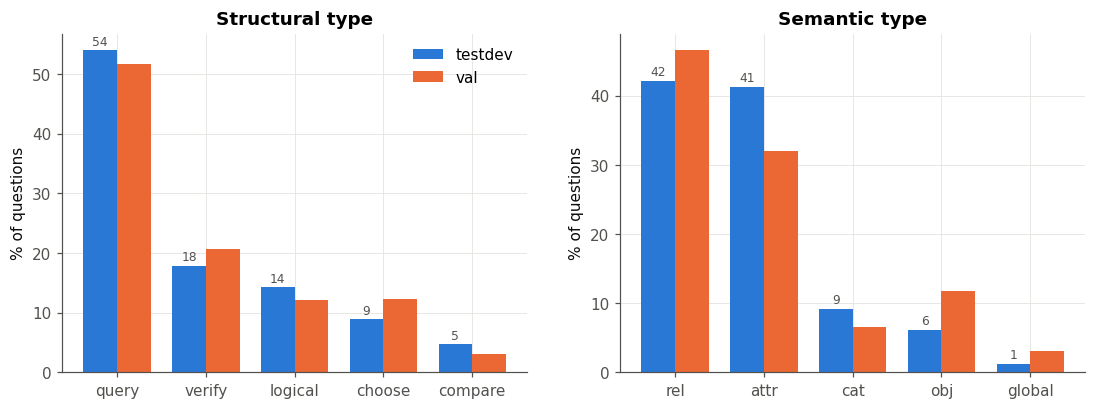

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["structural", "semantic"]):
    share = pd.DataFrame({
        "testdev": test[col].value_counts(normalize=True),
        "val": val[col].value_counts(normalize=True),
    }).sort_values("testdev", ascending=False) * 100
    x = np.arange(len(share)); w = 0.38
    ax.bar(x - w/2, share["testdev"], w, color=TEST_C, label="testdev")
    ax.bar(x + w/2, share["val"], w, color=VAL_C, label="val")
    for i, v in enumerate(share["testdev"]):
        ax.text(i - w/2, v + 0.8, f"{v:.0f}", ha="center", fontsize=8, color=MUTED)
    ax.set_xticks(x, share.index)
    ax.set_ylabel("% of questions")
    ax.set_title(f"{col.capitalize()} type")
axes[0].legend()
savefig("01_question_types")

## 7 · How the two type labels combine
- Each cell = number of testdev questions with that structural × semantic pair.
- These cells are the **strata** used for sampling in Step 11.

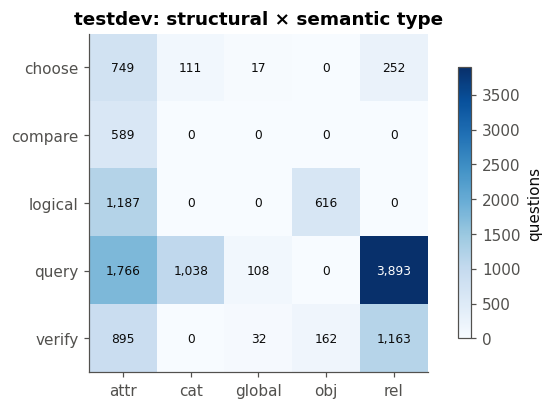

15 non-empty strata


In [8]:
ct = pd.crosstab(test.structural, test.semantic)
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(ct.values, cmap="Blues")
ax.set_xticks(range(ct.shape[1]), ct.columns)
ax.set_yticks(range(ct.shape[0]), ct.index)
ax.grid(False)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        v = ct.values[i, j]
        ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=8,
                color="white" if v > ct.values.max() * 0.55 else INK)
ax.set_title("testdev: structural × semantic type")
fig.colorbar(im, ax=ax, shrink=0.8, label="questions")
savefig("01_type_crosstab")
print(f"{(ct > 0).sum().sum()} non-empty strata")

## 8 · Reasoning depth
- `n_steps` = operations in the question's program (select → relate → query …).
- Key for hypothesis H3: does our method help more on deeper questions?
- Right panel: how depth differs across structural types.

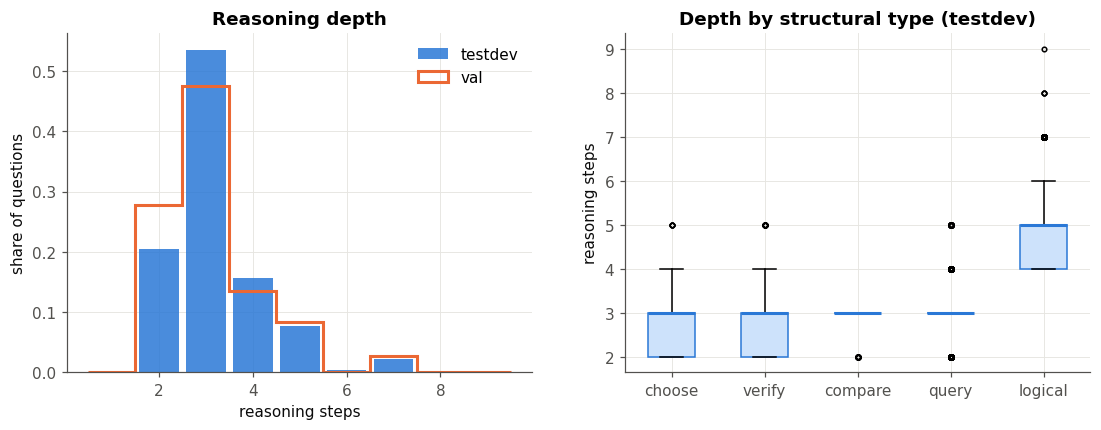

,mean,50%,min,max
structural,,,,
choose,2.63,3.0,2.0,5.0
compare,2.96,3.0,2.0,3.0
logical,5.00,5.0,4.0,9.0
query,3.02,3.0,2.0,5.0
verify,2.69,3.0,2.0,5.0


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.arange(0.5, max(test.n_steps.max(), val.n_steps.max()) + 1.5)
axes[0].hist(test.n_steps, bins=bins, density=True, color=TEST_C, alpha=0.85, label="testdev", rwidth=0.85)
axes[0].hist(val.n_steps, bins=bins, density=True, histtype="step", color=VAL_C, linewidth=2, label="val")
axes[0].set_xlabel("reasoning steps"); axes[0].set_ylabel("share of questions")
axes[0].set_title("Reasoning depth"); axes[0].legend()

order = test.groupby("structural").n_steps.mean().sort_values().index
axes[1].boxplot([test.loc[test.structural == s, "n_steps"] for s in order],
                widths=0.5, patch_artist=True,
                boxprops=dict(facecolor="#cde2fb", edgecolor=TEST_C),
                medianprops=dict(color=TEST_C, linewidth=2), flierprops=dict(markersize=3))
axes[1].set_xticks(range(1, len(order) + 1), order)
axes[1].set_ylabel("reasoning steps"); axes[1].set_title("Depth by structural type (testdev)")
savefig("01_reasoning_depth")
test.groupby("structural").n_steps.describe()[["mean", "50%", "min", "max"]].round(2)

## 9 · Answer distribution
- Left: the 25 most frequent answers.
- Right: rank vs frequency on log scales → a **long tail**: few answers are common, most are rare.
- Matters for us: rare answers are where a single greedy guess fails most.

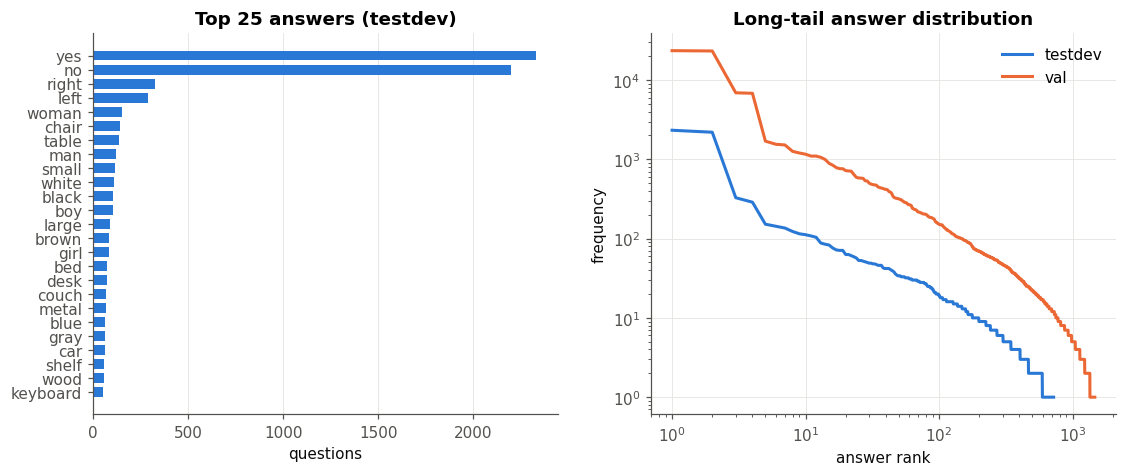

722 unique answers; top 10 cover 47%, top 100 cover 75%
answers seen only once: 129


In [10]:
counts = test.answer.value_counts()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
top = counts.head(25)[::-1]
axes[0].barh(top.index, top.values, color=TEST_C, height=0.7)
axes[0].set_xlabel("questions"); axes[0].set_title("Top 25 answers (testdev)")
axes[0].grid(axis="y", visible=False)

for df, c, name in [(test, TEST_C, "testdev"), (val, VAL_C, "val")]:
    vc = df.answer.value_counts().values
    axes[1].loglog(np.arange(1, len(vc) + 1), vc, color=c, linewidth=2, label=name)
axes[1].set_xlabel("answer rank"); axes[1].set_ylabel("frequency")
axes[1].set_title("Long-tail answer distribution"); axes[1].legend()
savefig("01_answers")

cover = (counts.cumsum() / counts.sum())
print(f"{counts.size} unique answers; top 10 cover {cover.iloc[9]:.0%}, top 100 cover {cover.iloc[min(99, len(cover)-1)]:.0%}")
print(f"answers seen only once: {(counts == 1).sum()}")

## 10 · Question length
- Longer questions usually describe more steps; checks that link.

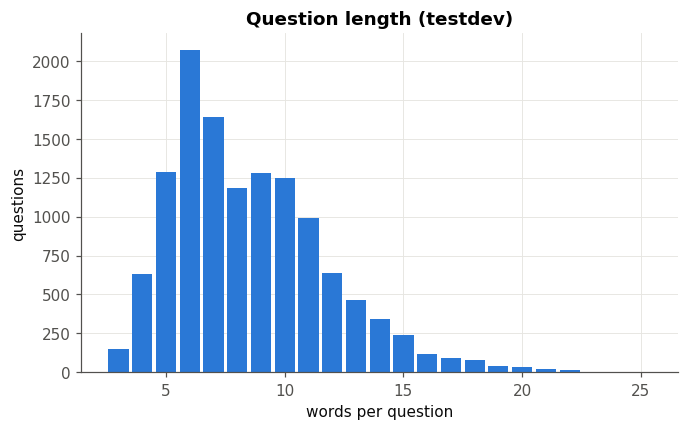

Spearman correlation, question length vs reasoning steps: 0.36


In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(test.q_words, bins=np.arange(2.5, test.q_words.max() + 1.5), color=TEST_C, rwidth=0.85)
ax.set_xlabel("words per question"); ax.set_ylabel("questions")
ax.set_title("Question length (testdev)")
savefig("01_question_length")
r = test[["q_words", "n_steps"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman correlation, question length vs reasoning steps: {r:.2f}")

## 11 · Scene graphs (val)
- Lists every object, its attributes and relations for each image.
- Used later to check whether our **grounding score** detects real objects (H4).
- Official release, 43 MB; testdev has no public scene graphs.

In [12]:
SG = f"{DATA}/raw/val_sceneGraphs.json"
if not os.path.exists(SG):
    os.makedirs(f"{DATA}/raw", exist_ok=True)
    !wget -q --show-progress -c https://downloads.cs.stanford.edu/nlp/data/gqa/sceneGraphs.zip -P /content
    !unzip -o -j /content/sceneGraphs.zip "*val_sceneGraphs.json" -d {DATA}/raw
sg = gqa.load_scene_graphs(SG)
sg_stats, obj_names = gqa.scene_graph_stats(sg)
print(f"{len(sg):,} val images with scene graphs")
sg_stats.describe().loc[["mean", "50%", "max"]].round(1)

sceneGraphs.zip     100%[===================>]  42.75M  5.10MB/s    in 5.2s    
Archive:  /content/sceneGraphs.zip
  inflating: /content/drive/MyDrive/cw-mpvr-data/raw/val_sceneGraphs.json  
10,696 val images with scene graphs


,n_objects,n_attributes,n_relations
mean,16.3,9.0,50.0
50%,16.0,8.0,34.0
max,97.0,50.0,1306.0


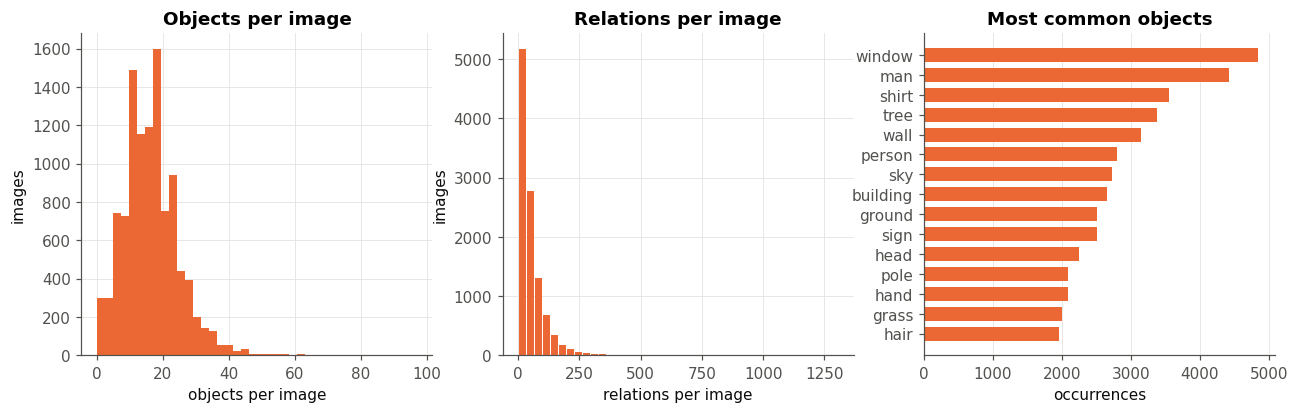

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, label in zip(axes[:2], ["n_objects", "n_relations"], ["objects", "relations"]):
    ax.hist(sg_stats[col], bins=40, color=VAL_C, rwidth=0.9)
    ax.set_xlabel(f"{label} per image"); ax.set_ylabel("images")
    ax.set_title(f"{label.capitalize()} per image")
names = pd.Series(obj_names).sort_values(ascending=False).head(15)[::-1]
axes[2].barh(names.index, names.values, color=VAL_C, height=0.7)
axes[2].set_xlabel("occurrences"); axes[2].set_title("Most common objects")
axes[2].grid(axis="y", visible=False)
savefig("01_scene_graphs")

## 12 · Build the samples
- **Proportional stratified sampling** over structural × semantic cells.
- Each cell keeps its share of the full split → overall accuracy stays an unbiased estimate.
- Fixed seed → anyone re-running gets the same questions.
- Saved to `data/` (small CSVs, in git) so every later notebook uses identical questions.

In [14]:
eval_df  = gqa.stratified_sample(test, cfg["data"]["n_eval"],  seed=SEED)
calib_df = gqa.stratified_sample(val,  cfg["data"]["n_calib"], seed=SEED)

cols = ["id", "imageId", "question", "answer", "structural", "semantic", "detailed", "n_steps"]
eval_df[cols].to_csv("data/eval_testdev.csv", index=False)
calib_df[cols].to_csv("data/calib_val.csv", index=False)

print(f"eval:  {len(eval_df):,} questions over {eval_df.imageId.nunique()} images")
print(f"calib: {len(calib_df):,} questions over {calib_df.imageId.nunique()} images")

eval:  2,500 questions over 392 images
calib: 500 questions over 478 images


## 13 · Is the sample representative?
- Checks variables we did **not** stratify on: reasoning depth and yes/no share.
- Chi-square test: a high p-value means no evidence the sample differs from the full split.

In [15]:
from scipy.stats import chisquare

def depth_test(sample, pop):
    b = lambda s: s.clip(upper=8)                   # pool 8+ steps so expected counts are not tiny
    p = b(pop.n_steps).value_counts(normalize=True).sort_index()
    o = b(sample.n_steps).value_counts().reindex(p.index, fill_value=0)
    return chisquare(o, p * len(sample)).pvalue

checks = pd.DataFrame({
    "yes/no % (full)":   [100 * test.answer.isin(["yes", "no"]).mean(), 100 * val.answer.isin(["yes", "no"]).mean()],
    "yes/no % (sample)": [100 * eval_df.answer.isin(["yes", "no"]).mean(), 100 * calib_df.answer.isin(["yes", "no"]).mean()],
    "mean steps (full)":   [test.n_steps.mean(), val.n_steps.mean()],
    "mean steps (sample)": [eval_df.n_steps.mean(), calib_df.n_steps.mean()],
    "depth χ² p-value": [depth_test(eval_df, test), depth_test(calib_df, val)],
}, index=["eval (testdev)", "calib (val)"]).round(3)
checks.to_csv("results/01_sample_checks.csv")
checks

,yes/no % (full),yes/no % (sample),mean steps (full),mean steps (sample),depth χ² p-value
eval (testdev),35.976,36.2,3.204,3.218,0.939
calib (val),35.400,35.8,3.133,3.162,0.921


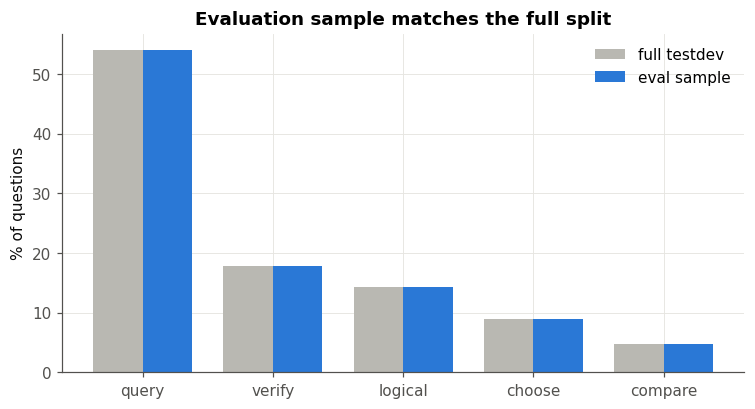

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
full = test.structural.value_counts(normalize=True) * 100
samp = eval_df.structural.value_counts(normalize=True).reindex(full.index) * 100
x = np.arange(len(full)); w = 0.38
ax.bar(x - w/2, full, w, color="#b9b8b2", label="full testdev")
ax.bar(x + w/2, samp, w, color=TEST_C, label="eval sample")
ax.set_xticks(x, full.index); ax.set_ylabel("% of questions")
ax.set_title("Evaluation sample matches the full split"); ax.legend()
savefig("01_sample_vs_full")

## 14 · Download the images we need
- Only images used by the two samples, copied as original bytes (no quality loss).
- testdev: ~66 MB total; val: ~1.4 GB is downloaded to Colab's disk, but only the calibration images are kept in Drive.
- Skips files that already exist, so re-running is quick.

In [17]:
from datasets import load_dataset, Image as HFImage
from tqdm.auto import tqdm

def fetch_images(config, split, needed, out_dir):
    os.makedirs(out_dir, exist_ok=True)
    missing = {i for i in needed if not os.path.exists(f"{out_dir}/{i}.jpg")}
    if not missing:
        print(f"{out_dir}: all {len(needed)} images present"); return
    ds = load_dataset(gqa.HF_REPO, config, split=split).cast_column("image", HFImage(decode=False))
    ds = ds.filter(lambda i: i in missing, input_columns="id")
    for r in tqdm(ds, desc=split):
        with open(f"{out_dir}/{r['id']}.jpg", "wb") as f:
            f.write(r["image"]["bytes"])
    print(f"{out_dir}: {len(os.listdir(out_dir))} images")

IMG = f"{DATA}/images"
fetch_images("testdev_balanced_images", "testdev", set(eval_df.imageId),  f"{IMG}/testdev")
fetch_images("val_balanced_images",     "val",     set(calib_df.imageId), f"{IMG}/val")

testdev_balanced_images/testdev-00000-of(…): reconstructing file:   0%|          |  0.00B / 65.6MB            

testdev_balanced_images/testdev-00000-of(…): downloading bytes:           |  0.00B            

Generating testdev split:   0%|          | 0/398 [00:00<?, ? examples/s]

Filter:   0%|          | 0/398 [00:00<?, ? examples/s]

testdev:   0%|          | 0/392 [00:00<?, ?it/s]

/content/drive/MyDrive/cw-mpvr-data/images/testdev: 392 images


... (6 outputs left out)

Generating val split:   0%|          | 0/10234 [00:00<?, ? examples/s]

Filter:   0%|          | 0/10234 [00:00<?, ? examples/s]

val:   0%|          | 0/478 [00:00<?, ?it/s]

/content/drive/MyDrive/cw-mpvr-data/images/val: 478 images


## 15 · Example questions
- Random evaluation questions with their image, type and depth.
- Shows what the model has to do: find objects, follow relations, answer.

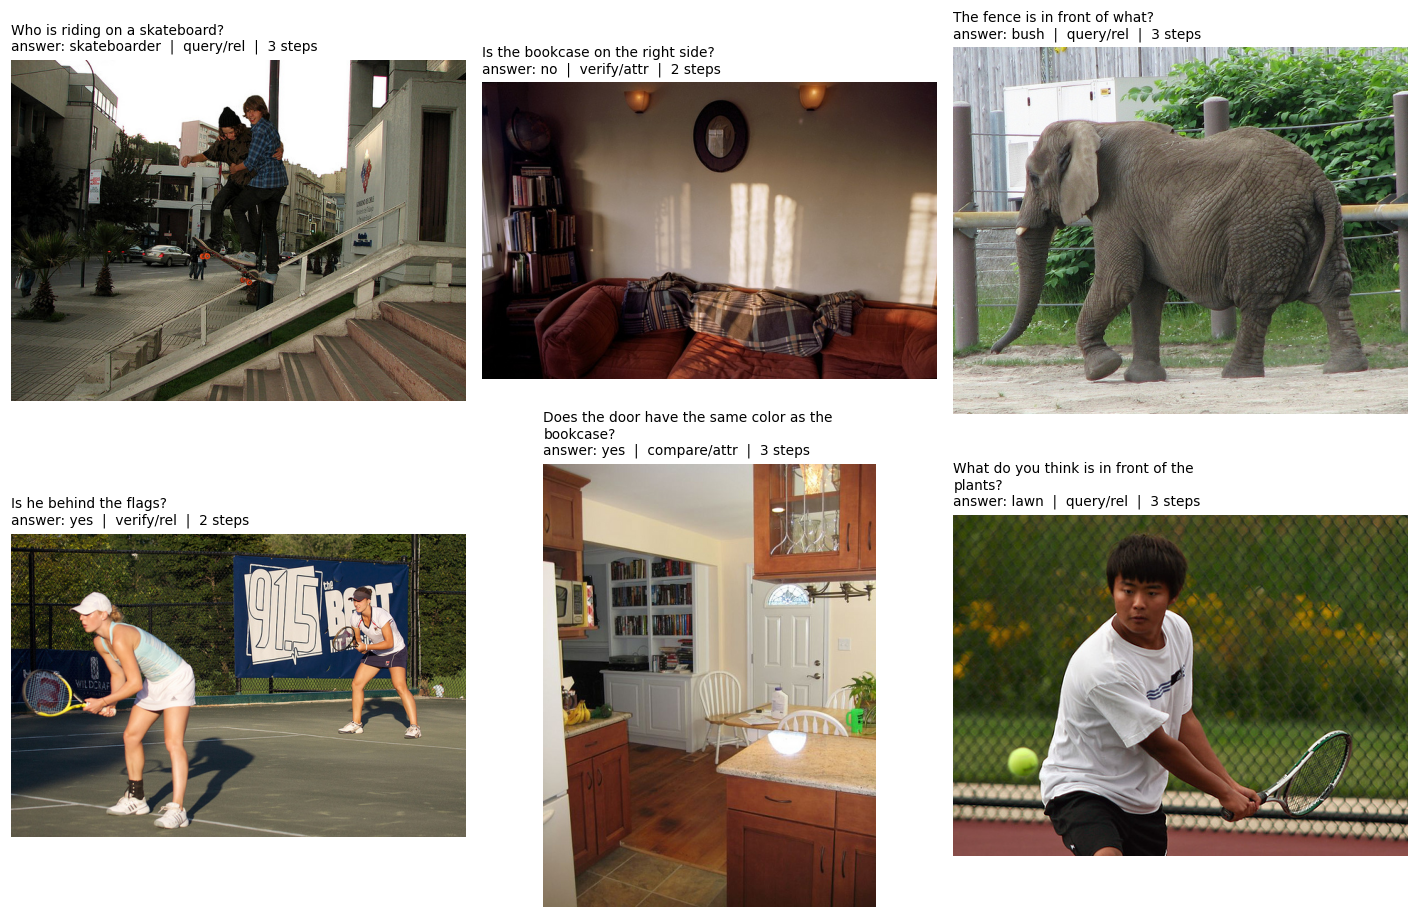

In [18]:
from PIL import Image
import textwrap

ex = eval_df.sample(6, random_state=SEED)
fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
for ax, (_, r) in zip(axes.flat, ex.iterrows()):
    ax.imshow(Image.open(f"{IMG}/testdev/{r.imageId}.jpg"))
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)
    q = "\n".join(textwrap.wrap(r.question, 42))
    ax.set_title(f"{q}\nanswer: {r.answer}  |  {r.structural}/{r.semantic}  |  {r.n_steps} steps",
                 fontsize=9, fontweight="normal", loc="left")
plt.tight_layout()
savefig("01_examples")

## Observations

**Size and answers**
- testdev: 12,578 questions over only 398 images (~32 questions per image); 722 unique answers.
- 36% of answers are yes/no; `yes` and `no` are almost equally frequent → the balanced split removes the "always say yes" shortcut.
- Long tail: top 10 answers cover 47%, top 100 cover 75%, and 129 answers appear only once → rare answers are where one greedy guess is most fragile.

**Question types**
- `query` dominates (54%); `compare` is smallest (5%). `rel` (42%) and `attr` (41%) are the main semantic types.
- Only 15 of 25 type combinations exist (`compare` is always about attributes; `logical` only attributes or objects).
- val has more `obj`, `verify` and `choose` questions than testdev → calibration and evaluation sets differ slightly; checked in notebook 04.
- Unequal type sizes → accuracy is reported **per type**, not only overall.

**Reasoning depth**
- Most questions need 2–5 steps; 3 steps is most common (~53%).
- `logical` questions are the deepest (median 5); other types sit around 3.
- **Depth and type are linked** → H3 (gain grows with depth) is tested within each type.
- Question length only moderately tracks depth (Spearman ρ = 0.36) → program length is the depth measure.

**Scene graphs (val)**
- Median image: 16 objects, 34 relations; some have over 1,000 relations.
- Cluttered scenes → a description can easily mention the wrong object; this is what the grounding score must catch.

**Samples**
- Yes/no share and depth match the full splits (χ² p = 0.94 eval, 0.92 calib) → representative.
- ~6 evaluation questions per image → not independent; the bootstrap in notebook 05 resamples **by image**.

## 16 · Save to GitHub
- Pushes this notebook, `src/gqa.py`, the sample CSVs, figures and tables.
- Images stay in Drive (not in git).

In [19]:
save_and_push("notebooks/01_data_eda.ipynb", "Add GQA data loading, EDA figures and stratified samples")

Saved notebook -> notebooks/01_data_eda.ipynb
A  data/calib_val.csv
A  data/eval_testdev.csv
A  figures/01_answers.png
A  figures/01_examples.png
A  figures/01_question_length.png
A  figures/01_question_types.png
A  figures/01_reasoning_depth.png
A  figures/01_sample_vs_full.png
A  figures/01_scene_graphs.png
A  figures/01_type_crosstab.png
A  notebooks/01_data_eda.ipynb
M  requirements.txt
A  results/01_dataset_summary.csv
A  results/01_sample_checks.csv
A  src/gqa.py
Pushed: Add GQA data loading, EDA figures and stratified samples


In [ ]:
save_and_push("notebooks/01_data_eda.ipynb", "Add dataset observations")